In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
print("Размер:", df.shape)

print("\nТипы колонок:")
print(df.dtypes)

print("\nПропуски:")
print(df.isna().sum())

print("\nОписательные статистики:")

df.describe()

Размер: (1338, 7)

Типы колонок:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Пропуски:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Описательные статистики:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [3]:
print("Mean charges:", df['charges'].mean())
print("Median charges:", df['charges'].median())

print("Skewness:", df['charges'].skew())

Mean charges: 13270.422265141257
Median charges: 9382.033
Skewness: 1.5158796580240388


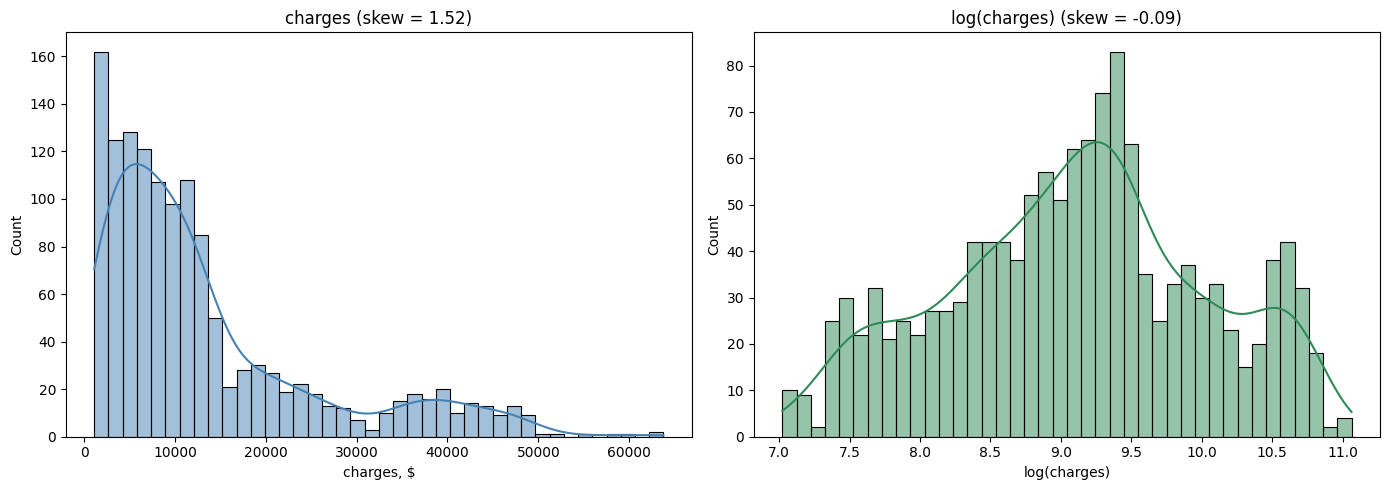

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['charges'], kde=True, bins=40, ax=axes[0], color='steelblue')
axes[0].set_title(f'charges (skew = {df["charges"].skew():.2f})')
axes[0].set_xlabel('charges, $')

df['log_charges'] = np.log(df['charges'])


sns.histplot(df['log_charges'], kde=True, bins=40, ax=axes[1], color='seagreen')
axes[1].set_title(f'log(charges) (skew = {df["log_charges"].skew():.2f})')
axes[1].set_xlabel('log(charges)')

plt.tight_layout()
plt.show()

In [5]:
df['log_charges'] = np.log(df['charges'])

print(df[['charges', 'log_charges']].head())
print("\nSkewness charges:     ", df['charges'].skew().round(3))
print("Skewness log_charges: ", df['log_charges'].skew().round(3))

       charges  log_charges
0  16884.92400     9.734176
1   1725.55230     7.453302
2   4449.46200     8.400538
3  21984.47061     9.998092
4   3866.85520     8.260197

Skewness charges:      1.516
Skewness log_charges:  -0.09


In [6]:
df_encoded = pd.get_dummies(df,columns=['sex', 'smoker', 'region'], drop_first=True)

print("Было колонок:", df.shape[1])
print("Стало колонок:", df_encoded.shape[1])

print("\nКолонки:")
print(df_encoded.columns.tolist())

df_encoded.head(3)

Было колонок: 8
Стало колонок: 10

Колонки:
['age', 'bmi', 'children', 'charges', 'log_charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


,age,bmi,children,charges,log_charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.90,0,16884.9240,9.734176,False,True,False,False,True
1,18,33.77,1,1725.5523,7.453302,True,False,False,True,False
2,28,33.00,3,4449.4620,8.400538,True,False,False,True,False


In [7]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(['charges', 'log_charges'], axis=1)

y = df_encoded['log_charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (1070, 8)
X_test:  (268, 8)
y_train: (1070,)
y_test:  (268,)


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Среднее возраста до scaling:   ", X_train['age'].mean().round(2))
print("Среднее возраста после scaling:", X_train_scaled[:, 0].mean().round(4))
print("Std после scaling:              ", X_train_scaled[:, 0].std().round(4))

print("\nX_train_scaled:", X_train_scaled.shape)
print("X_test_scaled: ", X_test_scaled.shape)

Среднее возраста до scaling:    39.36
Среднее возраста после scaling: -0.0
Std после scaling:               1.0

X_train_scaled: (1070, 8)
X_test_scaled:  (268, 8)


In [9]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

models = {
    'LinearRegression': (LinearRegression(), X_train_scaled, X_test_scaled),
    'Ridge':            (Ridge(alpha=1.0),   X_train_scaled, X_test_scaled),
    'RandomForest':     (RandomForestRegressor(n_estimators=100, random_state=42),
                         X_train, X_test),
}

results = {}

for name, (model, X_tr, X_te) in models.items():

    model.fit(X_tr, y_train)
    y_pred_log = model.predict(X_te)
    y_pred = np.exp(y_pred_log)
    y_test_real = np.exp(y_test)

    r2 = r2_score(y_test, y_pred_log)
    rmse = np.sqrt(mean_squared_error(y_test_real, y_pred))
    mae = mean_absolute_error(y_test_real, y_pred)

    results[name] = {'R²': r2, 'RMSE ($)': rmse, 'MAE ($)': mae}

    print(f"=== {name} ===")
    print(f"R²:   {r2:.4f}")
    print(f"RMSE: ${rmse:,.2f}")
    print(f"MAE:  ${mae:,.2f}")
    print()


results_df = pd.DataFrame(results).T
print("Сравнение моделей:")
print(results_df.round(4))

=== LinearRegression ===
R²:   0.8047
RMSE: $7,815.31
MAE:  $3,888.77

=== Ridge ===
R²:   0.8047
RMSE: $7,800.36
MAE:  $3,885.51

=== RandomForest ===
R²:   0.8456
RMSE: $4,364.20
MAE:  $2,086.91

Сравнение моделей:
                      R²   RMSE ($)    MAE ($)
LinearRegression  0.8047  7815.3073  3888.7708
Ridge             0.8047  7800.3648  3885.5086
RandomForest      0.8456  4364.2017  2086.9113


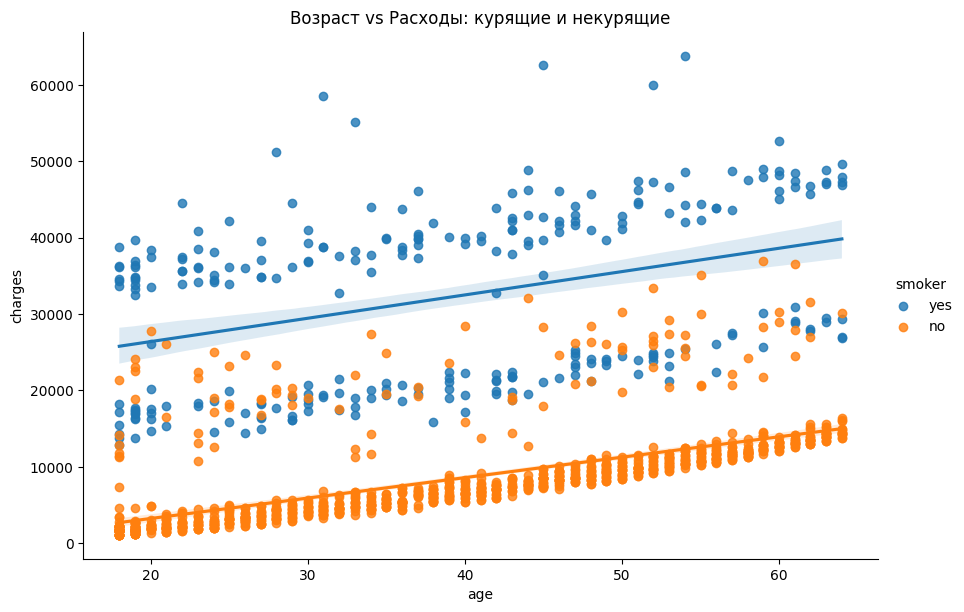

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.lmplot(data=df, x='age', y='charges', hue='smoker',
           aspect=1.5, height=6)
plt.title('Возраст vs Расходы: курящие и некурящие')
plt.show()

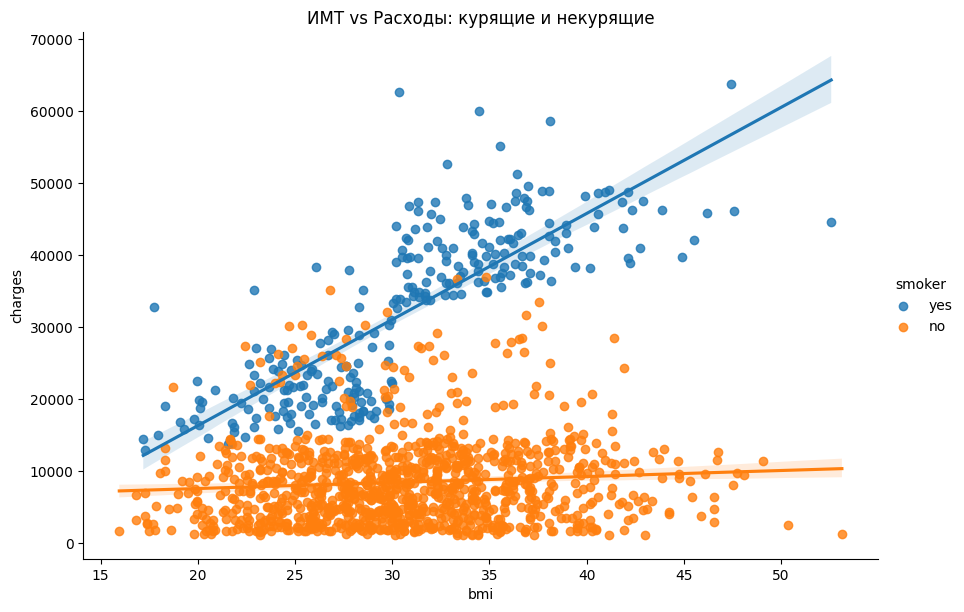

In [11]:
sns.lmplot(data=df, x='bmi', y='charges', hue='smoker',
           aspect=1.5, height=6)
plt.title('ИМТ vs Расходы: курящие и некурящие')
plt.show()

In [12]:
lr = LinearRegression().fit(X_train_scaled, y_train)
rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)

y_test_real = np.exp(y_test)
y_pred_lr = np.exp(lr.predict(X_test_scaled))
y_pred_rf = np.exp(rf.predict(X_test))

errors_lr = np.abs(y_test_real - y_pred_lr)
errors_rf = np.abs(y_test_real - y_pred_rf)

threshold = np.percentile(y_test_real, 90)
mask = y_test_real >= threshold

print("Топ-10% дорогих клиентов:")
print(f"  MAE LinearRegression: ${errors_lr[mask].mean():,.0f}")
print(f"  MAE RandomForest:     ${errors_rf[mask].mean():,.0f}")

print("\nОстальные 90% клиентов:")
print(f"  MAE LinearRegression: ${errors_lr[~mask].mean():,.0f}")
print(f"  MAE RandomForest:     ${errors_rf[~mask].mean():,.0f}")

Топ-10% дорогих клиентов:
  MAE LinearRegression: $9,474
  MAE RandomForest:     $2,956

Остальные 90% клиентов:
  MAE LinearRegression: $3,263
  MAE RandomForest:     $1,990


In [13]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    RandomForestRegressor(n_estimators=100, random_state=42),
    X, y,
    cv=5,
    scoring='r2'
)


print("R² по фолдам:", cv_scores.round(4))
print(f"Средний R²:   {cv_scores.mean():.4f}")
print(f"Стандартное отклонение: {cv_scores.std():.4f}")

R² по фолдам: [0.8486 0.6946 0.8735 0.8253 0.786 ]
Средний R²:   0.8056
Стандартное отклонение: 0.0625


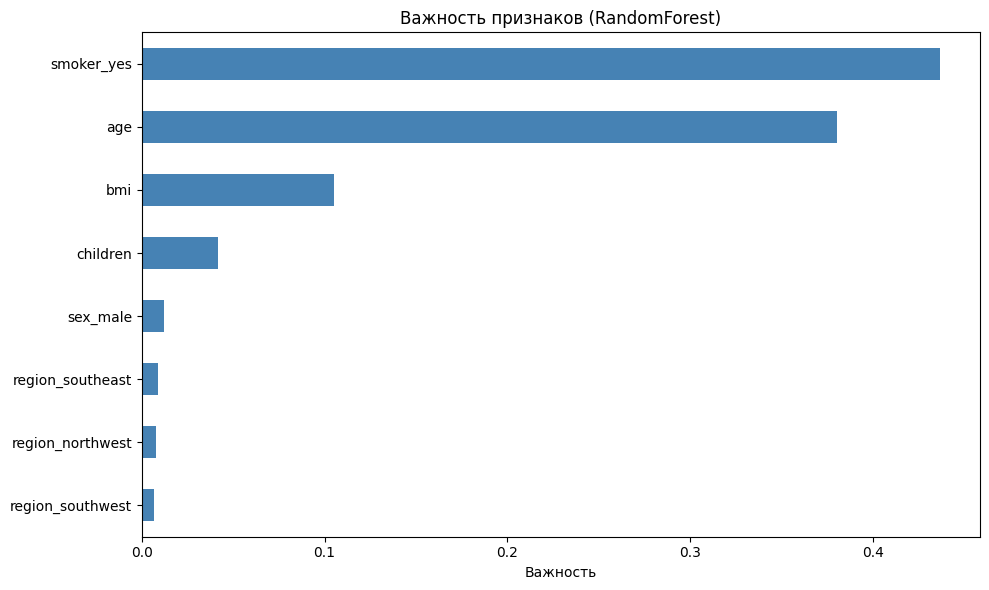

smoker_yes          0.4368
age                 0.3805
bmi                 0.1053
children            0.0419
sex_male            0.0121
region_southeast    0.0089
region_northwest    0.0076
region_southwest    0.0068
dtype: float64


In [14]:
rf_final = RandomForestRegressor(n_estimators=100, random_state=42)
rf_final.fit(X_train, y_train)

import pandas as pd
import matplotlib.pyplot as plt

importances = pd.Series(rf_final.feature_importances_, index=X.columns)
importances.sort_values().plot(kind='barh', figsize=(10, 6), color='steelblue')
plt.title('Важность признаков (RandomForest)')
plt.xlabel('Важность')
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False).round(4))